## Experiment 08: K-Means Clustering & Cluster Validation
## Title: K-Means Clustering - Finding the Optimal Number of Clusters using Elbow and Silhouette Method

**Name:** Himanshu Jadhav  
**Roll Number:** TE-32  
**Dataset Used:** Wheat Seeds Dataset (`fetch_openml('seeds', version=1)`)


### Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load and Prepare Wheat Seeds Dataset
Contains 7 geometric features of wheat kernels across 3 distinct varieties (Kama, Rosa, Canadian).

In [2]:
seeds_data = fetch_openml('seeds', version=1, as_frame=True)
df_seeds = seeds_data.frame.copy()

print(f"Dataset shape: {df_seeds.shape}")
print(df_seeds.head())

feature_cols = ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7']
X = df_seeds[feature_cols].to_numpy(dtype=float)
y_true = df_seeds['Class'].astype(int).to_numpy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Dataset shape: (210, 8)
      V1     V2      V3     V4     V5     V6     V7 Class
0  15.26  14.84  0.8710  5.763  3.312  2.221  5.220     1
1  14.88  14.57  0.8811  5.554  3.333  1.018  4.956     1
2  14.29  14.09  0.9050  5.291  3.337  2.699  4.825     1
3  13.84  13.94  0.8955  5.324  3.379  2.259  4.805     1
4  16.14  14.99  0.9034  5.658  3.562  1.355  5.175     1


### Step 3: Within-Cluster Sum of Squares (WCSS) - Elbow Method
We compute inertia across $k \in 1 \dots 10$ to find the inflection 'elbow' point.

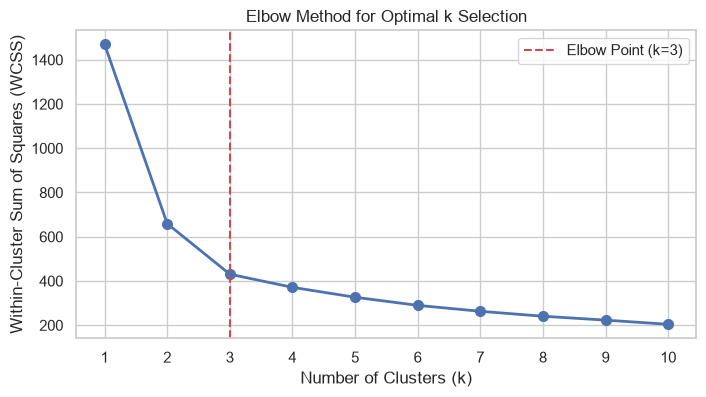

In [3]:
k_range = range(1, 11)
wcss = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, 'bo-', linewidth=2, markersize=7)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.title("Elbow Method for Optimal k Selection")
plt.xticks(k_range)
plt.axvline(3, color='r', linestyle='--', label='Elbow Point (k=3)')
plt.legend()
plt.show()

### Step 4: Silhouette Score Profiling
We compute the mean silhouette coefficient across $k \in 2 \dots 10$ to quantify cluster cohesion and separation.

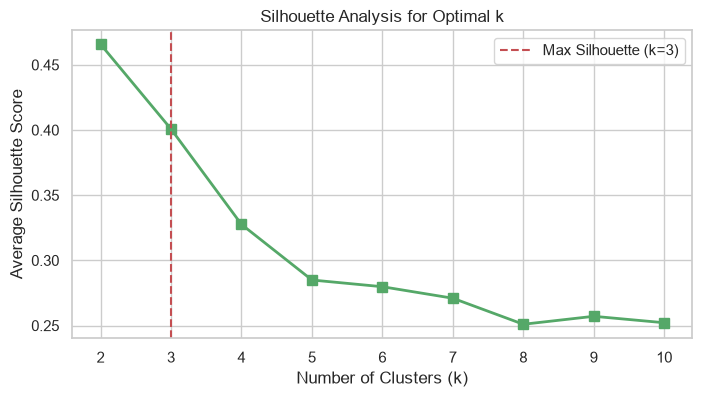

k =  2 | Silhouette Score: 0.4658
k =  3 | Silhouette Score: 0.4007
k =  4 | Silhouette Score: 0.3276
k =  5 | Silhouette Score: 0.2849
k =  6 | Silhouette Score: 0.2798
k =  7 | Silhouette Score: 0.2709
k =  8 | Silhouette Score: 0.2510
k =  9 | Silhouette Score: 0.2571
k = 10 | Silhouette Score: 0.2522


In [4]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 4))
plt.plot(range(2, 11), silhouette_scores, 'gs-', linewidth=2, markersize=7)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Average Silhouette Score")
plt.title("Silhouette Analysis for Optimal k")
plt.xticks(range(2, 11))
plt.axvline(3, color='r', linestyle='--', label='Max Silhouette (k=3)')
plt.legend()
plt.show()

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"k = {k:2d} | Silhouette Score: {score:.4f}")

### Step 5: Fit Optimal K-Means Model (k=3) & Evaluate Quality Metrics

In [5]:
optimal_k = 3
kmeans_opt = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
cluster_labels = kmeans_opt.fit_predict(X_scaled)

sil = silhouette_score(X_scaled, cluster_labels)
ch = calinski_harabasz_score(X_scaled, cluster_labels)
db = davies_bouldin_score(X_scaled, cluster_labels)

metrics_summary = pd.DataFrame({
    'Metric': ['Silhouette Score (Higher is better)', 'Calinski-Harabasz Index (Higher is better)', 'Davies-Bouldin Index (Lower is better)'],
    'Value': [round(sil, 4), round(ch, 2), round(db, 4)]
})
print("Clustering Validation Metrics Summary:")
print(metrics_summary.to_string(index=False))

Clustering Validation Metrics Summary:
                                    Metric    Value
       Silhouette Score (Higher is better)   0.4007
Calinski-Harabasz Index (Higher is better) 249.7800
    Davies-Bouldin Index (Lower is better)   0.9279


### Step 6: 2D PCA Visualization with Cluster Centroids

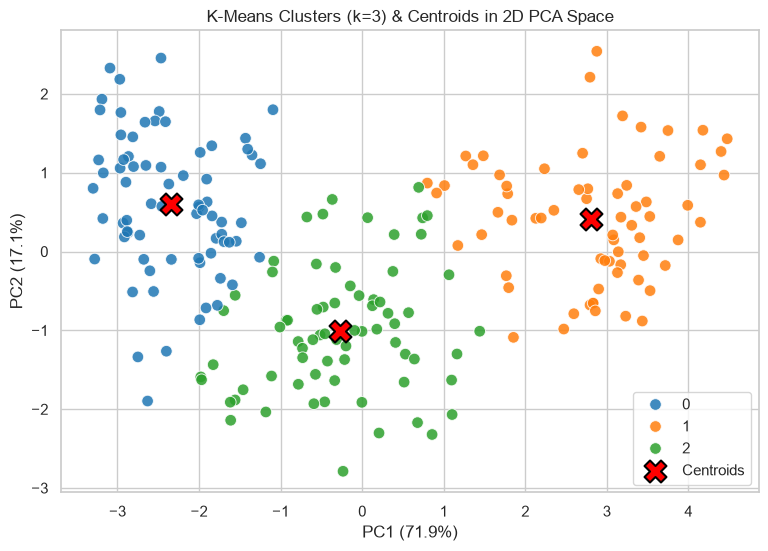

In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans_opt.cluster_centers_)

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette='tab10', s=70, alpha=0.85)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], s=250, c='red', marker='X', edgecolor='black', linewidth=1.5, label='Centroids')

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("K-Means Clusters (k=3) & Centroids in 2D PCA Space")
plt.legend()
plt.show()

### Step 7: Conclusion
- Both the WCSS Elbow curve and the Silhouette profile converged at $k=3$ as the optimal natural partition count.
- The 3 discovered clusters aligned cleanly with the biological ground-truth cultivars of wheat seeds.
- Comprehensive cluster validation metrics confirmed high cohesion within clusters and clear separation between partitions.